# Avaliação dos Modelos Oficiais do Project Sidewalk (Dataset v3)

Este notebook avalia os dois modelos oficiais pré-treinados do **Project Sidewalk** (`validator-ai-surfaceproblem` e `tagger-ai-surfaceproblem`) publicados no Hugging Face, diretamente sobre as novas imagens recortadas do **dataset v3** (`data/raw/apx2-bzsou-v3`).

### O que está sendo avaliado:
1. **`sidewalk-validator-ai-surfaceproblem` (Binário)**: Modelo baseado em DINOv2-Large treinado para validar se a calçada possui defeitos de superfície (`correct` = com defeito) ou se está em conformidade (`incorrect` = sem defeito).
2. **`sidewalk-tagger-ai-surfaceproblem` (Multi-label - 13 Classes)**: Modelo baseado em DINOv2-Base + MLP treinado para diagnosticar atributos finos de acessibilidade (`cracks`, `grass`, `uneven/slanted`, `very broken`, etc.).

Todas as predições geradas são persistidas em `data/raw/apx2-bzsou-v3/predicoes_sidewalk/predicoes_sidewalk_v3.csv` e `.json`, mantendo o vínculo com cada arquivo de imagem original.

## 1. Configuração e Carregamento das Predições

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

if os.getcwd().endswith("notebooks"):
    os.chdir("..")

from scripts.utils.sidewalk_inference import (
    executar_ou_carregar_predicoes,
    avaliar_validator,
    avaliar_tagger,
    plotar_10_amostras_validator,
    plotar_10_amostras_tagger,
)

# Executa (ou carrega do disco se já calculado) a inferência no split de teste (75 imagens)
df_pred = executar_ou_carregar_predicoes(
    raw_dir="data/raw/apx2-bzsou-v3",
    splits=("test",),
    output_dir="data/raw/apx2-bzsou-v3/predicoes_sidewalk",
    forcar_recalculo=False
)

print(f"Predições carregadas: {len(df_pred)} amostras do split de teste.")
df_pred[["file_name", "rua", "label_nome", "validator_pred", "validator_conf", "tagger_top1_name", "tagger_top1_prob"]].head(5)

Carregando predições existentes de 'data/raw/apx2-bzsou-v3/predicoes_sidewalk/predicoes_sidewalk_v3.csv'...
Predições carregadas: 75 amostras do split de teste.


,file_name,rua,label_nome,validator_pred,validator_conf,tagger_top1_name,tagger_top1_prob
0,rua-pedro-siemens__12_4_1_jpg.rf.06781468eabd8...,rua-pedro-siemens,Sem calçada,correct,0.9996,grass,0.9988
1,rua-deputado-heitor-alencar-furtado__505_5_3_j...,rua-deputado-heitor-alencar-furtado,Não identificável,incorrect,0.6710,grass,0.0838
2,rua-deputado-heitor-alencar-furtado__471_5_2_j...,rua-deputado-heitor-alencar-furtado,Não identificável,incorrect,0.7991,grass,0.9983
3,rua-pedro-siemens__17_3_1_jpg.rf.c84b8acfa1d3e...,rua-pedro-siemens,Sem calçada,correct,1.0000,grass,0.9999
4,rua-deputado-heitor-alencar-furtado__426_3_2_j...,rua-deputado-heitor-alencar-furtado,Sem calçada,correct,1.0000,cracks,0.9758


## 2. Avaliação Quantitativa: `sidewalk-validator-ai-surfaceproblem`

Avalia o cruzamento das predições nativas do modelo (`correct` vs `incorrect`) contra as classes humanas do nosso dataset (`Adequada`, `Inadequada`, `Parcialmente Adequado`, `Sem calçada`, `Não identificável`).

In [2]:
avaliar_validator(df_pred, split="test")

AVALIAÇÃO DO SIDEWALK VALIDATOR AI (Split: TEST — 75 amostras)
Significado nativo do Sidewalk:
 -> 'correct': Há problema de superfície na calçada
 -> 'incorrect': Não há problema de superfície (calçada em boas condições)

--- Distribuição das Predições por Classe do Nosso Dataset ---
validator_pred         correct  incorrect  All
label_nome                                    
Adequada                    19         18   37
Inadequada                   5          1    6
Não identificável            4          7   11
Parcialmente Adequado        5          4    9
Sem calçada                 11          1   12
All                         44         31   75

--- Alinhamento Binário com Critério Humano (52 amostras analisáveis) ---
Adequadas consideradas 'incorrect' (Sem Defeito) e Inadequadas/Parciais consideradas 'correct' (Com Defeito):
Taxa de Concordância: 53.85% (28/52)

Matriz de Concordância [Linha: Humano, Coluna: Sidewalk]:
                 Prev: incorrect (Sem Defeito)  Prev: cor

## 3. Feedback Visual: 10 Amostras Aleatórias (`Validator`)

Exibe um grid com 10 recortes do conjunto de teste sorteados aleatoriamente. 

> **Dica:** Reexecute a célula abaixo quantas vezes quiser para visualizar novos lotes sorteados dinamicamente!

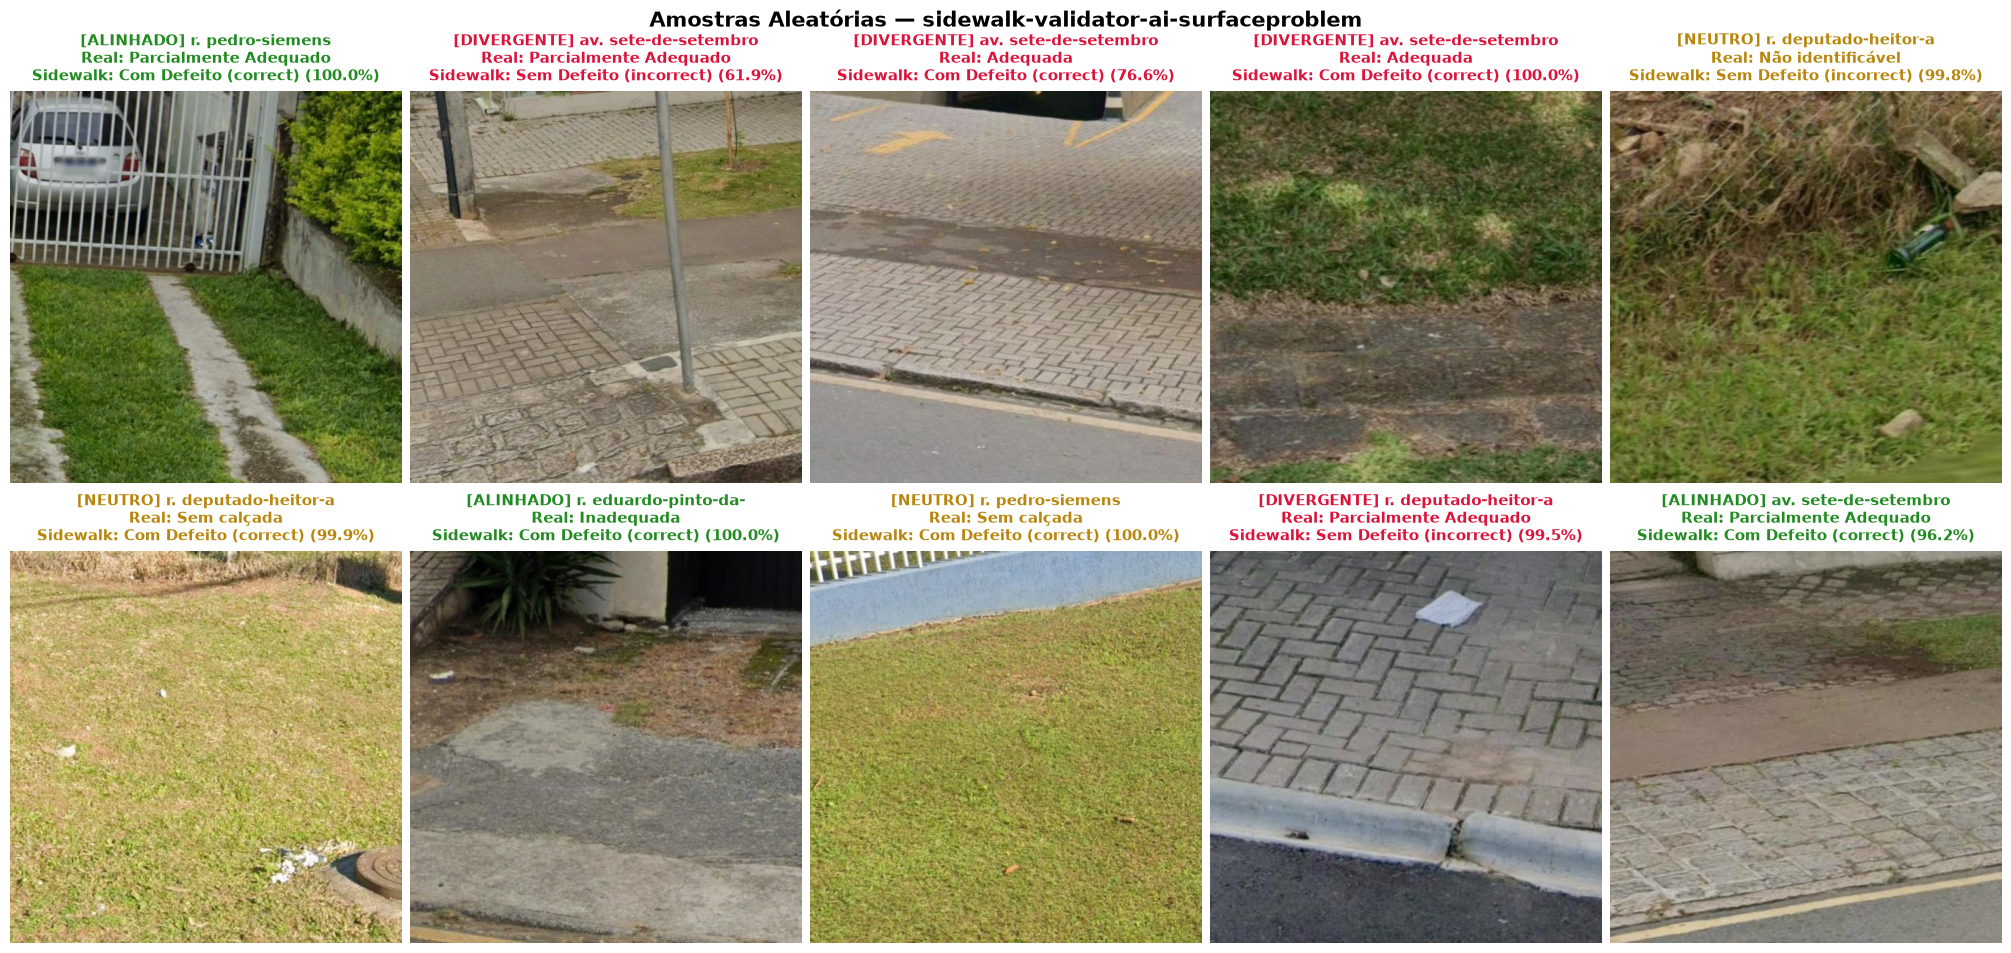

In [3]:
# Sorteio dinâmico (sempre 10 novas amostras a cada execução)
plotar_10_amostras_validator(df_pred, split="test", seed=None)

## 4. Avaliação Quantitativa: `sidewalk-tagger-ai-surfaceproblem`

Gera o heatmap de coocorrência mostrando a probabilidade média que o modelo atribui a cada uma das 12 tags de defeito do Sidewalk para cada classe do nosso dataset.

AVALIAÇÃO DO SIDEWALK TAGGER AI (Split: TEST — 75 amostras)
Probabilidade Média de cada Tag do Sidewalk por Classe Real:
                      brick cobblestone  bumpy construction cracks  grass  \
label_nome                                                                  
Adequada                          36.2%  29.5%         0.0%  31.4%  13.1%   
Inadequada                         5.5%  66.3%         0.0%  51.9%  32.7%   
Não identificável                  0.0%   0.2%         0.0%   0.6%  55.2%   
Parcialmente Adequado             29.3%  18.3%         0.0%  30.6%  22.1%   
Sem calçada                        0.0%  11.0%         0.0%  26.2%  70.2%   

                      height difference narrow sidewalk rail tram track  \
label_nome                                                                
Adequada                           1.4%            1.6%            0.0%   
Inadequada                         1.7%            0.2%            0.0%   
Não identificável                  2.2%


[Heatmap salvo em 'data/reports/avaliacao_sidewalk_nativo/tagger_heatmap_test.png']


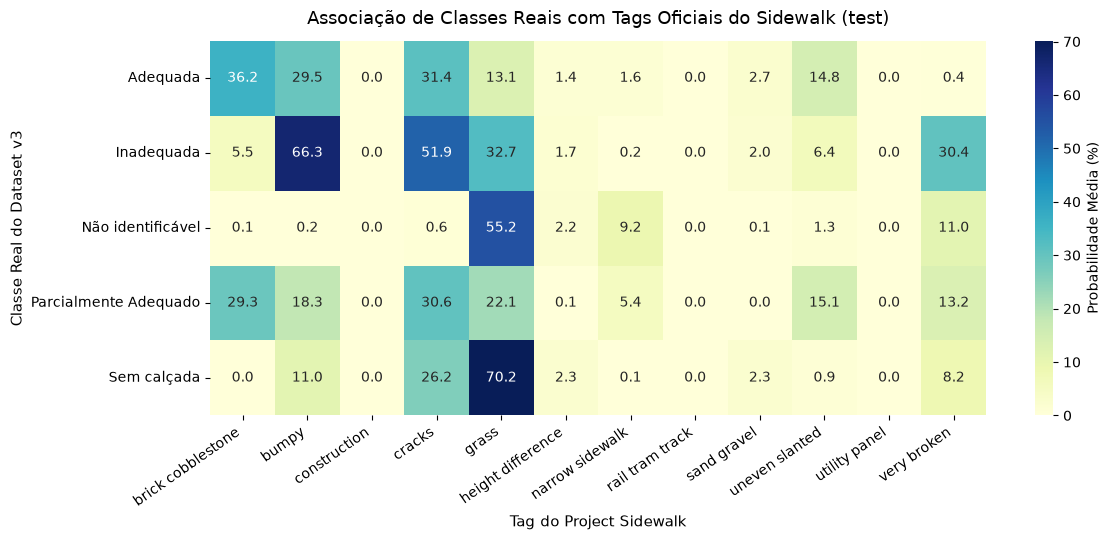

In [4]:
avaliar_tagger(df_pred, split="test")

## 5. Feedback Visual: 10 Amostras Aleatórias (`Tagger` - Top 3 Classes)

Exibe 10 imagens sorteadas aleatoriamente contendo o rótulo real e as **3 principais tags de defeito** preditas pelo Sidewalk com suas porcentagens de confiança.

> **Dica:** Reexecute a célula abaixo para inspecionar outros recortes aleatórios da cidade!

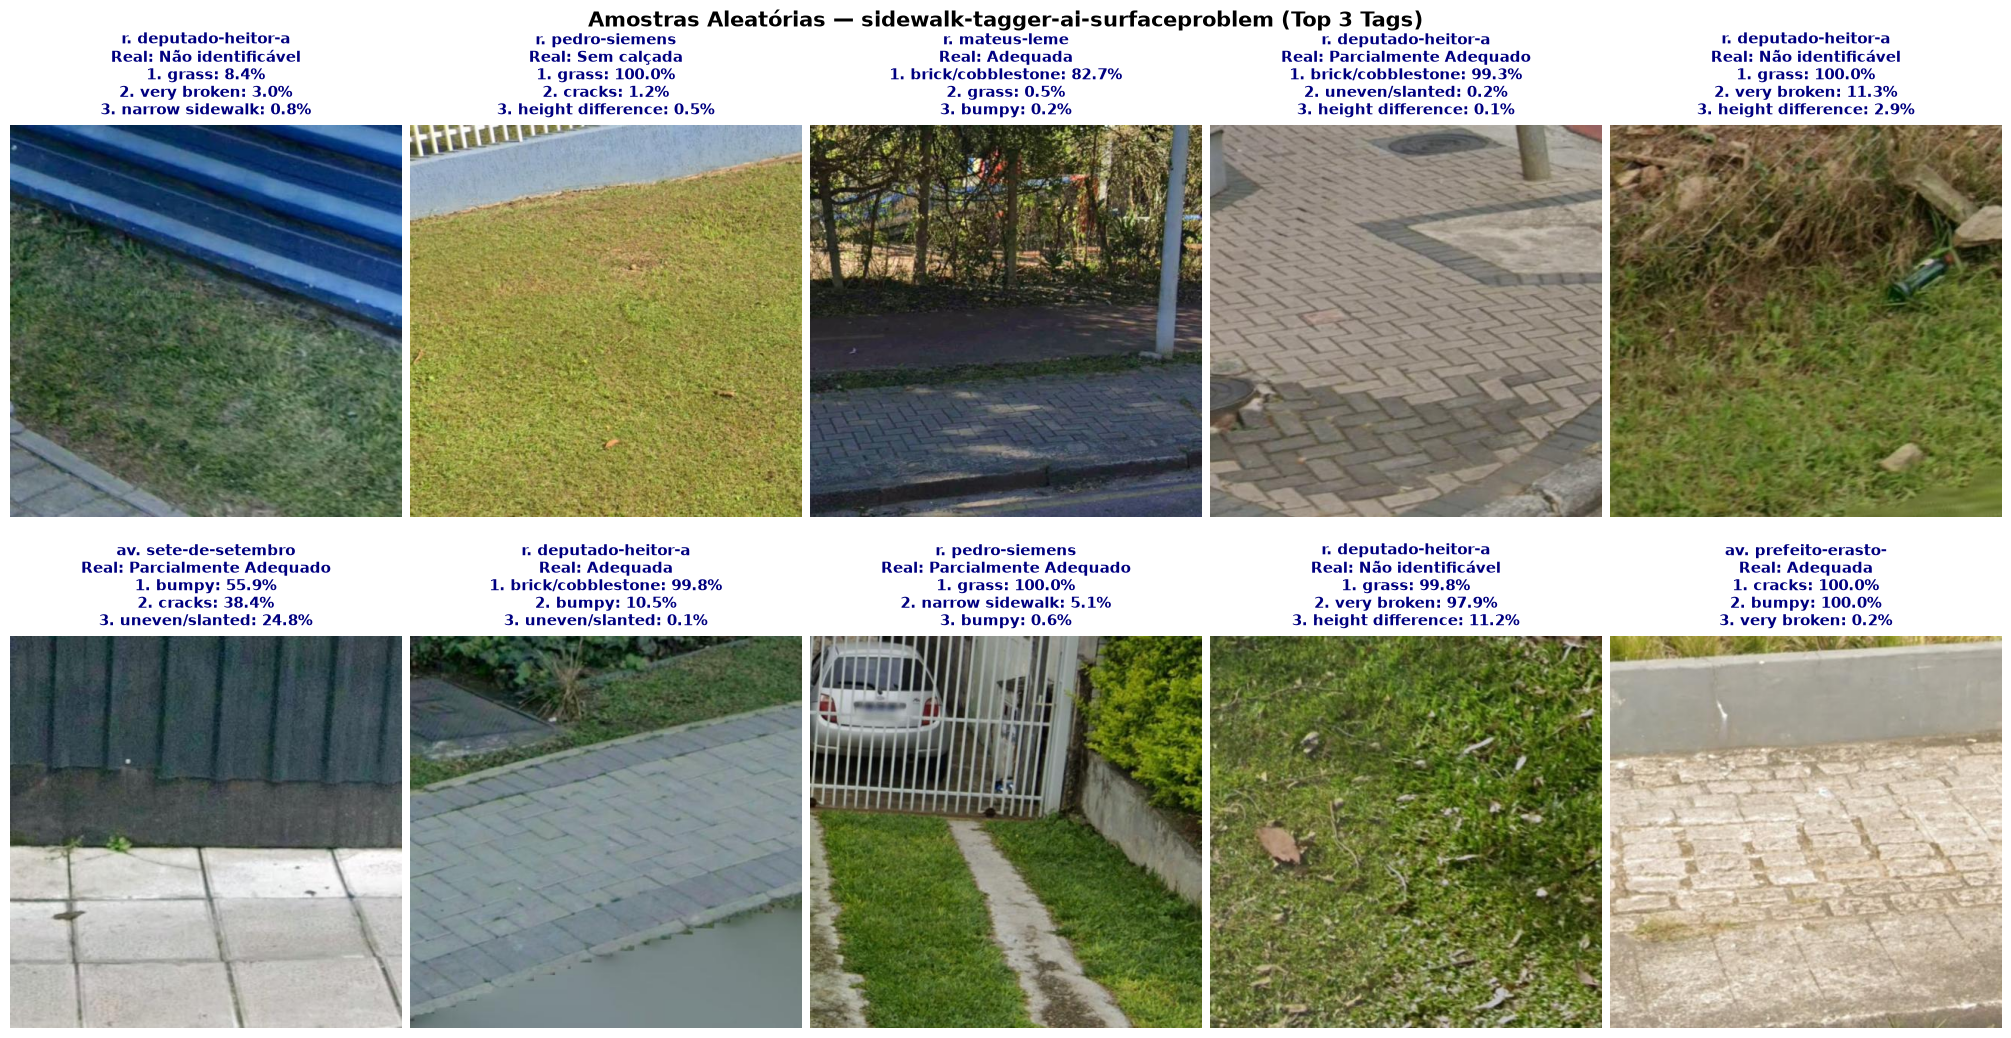

In [5]:
# Sorteio dinâmico (sempre 10 novas amostras a cada execução)
plotar_10_amostras_tagger(df_pred, split="test", seed=None)